In [ ]:
from connectome_all import *



threshold = 256
pipe_shift = 10
K = 10 
PIPE_K = 1

voltages = [0] * N
last_spikes = [0] * N

pokes = [[1,0]] * 20 + [[0,0]] * 20 + [[0,1]] * 20 + [[0,0]] * 20
poke_connections = [
    [(ALML, 300), (ALMR, 300), (AVM, 300)],
    [(PLML, 300), (PLMR, 300), (PVM, 300)]
]

def neuron_model(total, v):
  spike = 0
  v = v - (v >> 3) + total
  if v >= threshold:      # fire when voltage crosses threshold
    v = 0                 # reset after spiking
    spike = 1
  return v, spike


all_voltages = [] #one entry per step: all 300 voltages
all_spikes = [] #one entry per step: all 300 spikes(0 or 1)

for step, row in enumerate(pokes):
  spikes = [0] * N
  totals = [0] * N

  # deliver last step's neuron spikes
  for i in range(N):
    if last_spikes[i] == 1:
      for target, weight in connections[i]:
        totals[target] += weight

  # deliver this step's pokes
  for p in range(len(poke_connections)):
    if row[p] == 1:
      for target, weight in poke_connections[p]:
        totals[target] += weight

  # pipes: spike packages from last steps spikes, plus flow from start-of-step voltages
  for a, b, size in pipes:
    if last_spikes[a] == 1:
      totals[b] += size * PIPE_K
    if last_spikes[b] == 1:
      totals[a] += size * PIPE_K
    flow = ((voltages[a] - voltages[b]) * size) >> pipe_shift
    totals[a] -= flow
    totals[b] += flow

  # update every neuron
  for t in range(N):
    voltages[t], spikes[t] = neuron_model(totals[t], voltages[t])

  # save outputs
  all_voltages.append(voltages.copy())
  all_spikes.append(spikes.copy())
  last_spikes = spikes
  
  fired = []
  for i in range(N):
    if spikes[i] == 1:
      fired.append(neurons[i])
  print(f"step {step:3d}  poke {row}  fired: {len(fired)} neurons")


step   0  poke [1, 0]  fired: 3 neurons
step   1  poke [1, 0]  fired: 3 neurons
step   2  poke [1, 0]  fired: 5 neurons
step   3  poke [1, 0]  fired: 3 neurons
step   4  poke [1, 0]  fired: 5 neurons
step   5  poke [1, 0]  fired: 5 neurons
step   6  poke [1, 0]  fired: 5 neurons
step   7  poke [1, 0]  fired: 4 neurons
step   8  poke [1, 0]  fired: 6 neurons
step   9  poke [1, 0]  fired: 7 neurons
step  10  poke [1, 0]  fired: 7 neurons
step  11  poke [1, 0]  fired: 5 neurons
step  12  poke [1, 0]  fired: 6 neurons
step  13  poke [1, 0]  fired: 9 neurons
step  14  poke [1, 0]  fired: 10 neurons
step  15  poke [1, 0]  fired: 9 neurons
step  16  poke [1, 0]  fired: 9 neurons
step  17  poke [1, 0]  fired: 7 neurons
step  18  poke [1, 0]  fired: 11 neurons
step  19  poke [1, 0]  fired: 10 neurons
step  20  poke [0, 0]  fired: 7 neurons
step  21  poke [0, 0]  fired: 3 neurons
step  22  poke [0, 0]  fired: 4 neurons
step  23  poke [0, 0]  fired: 3 neurons
step  24  poke [0, 0]  fired: 4 neuro

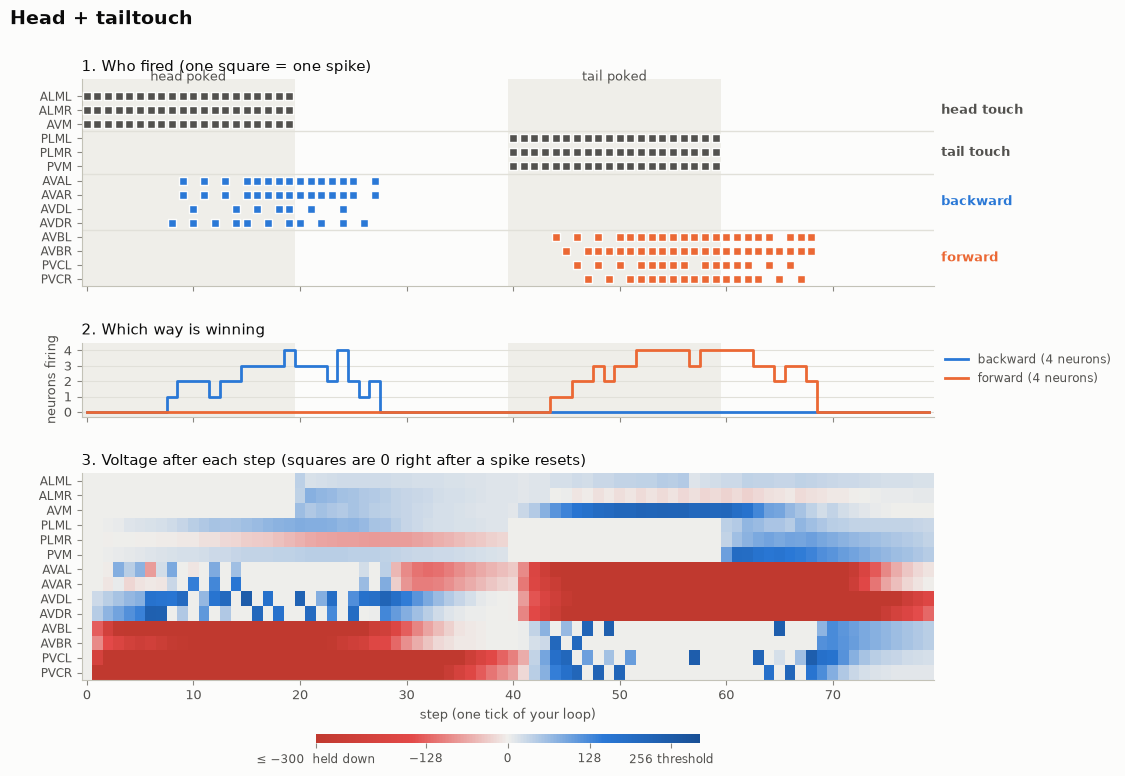

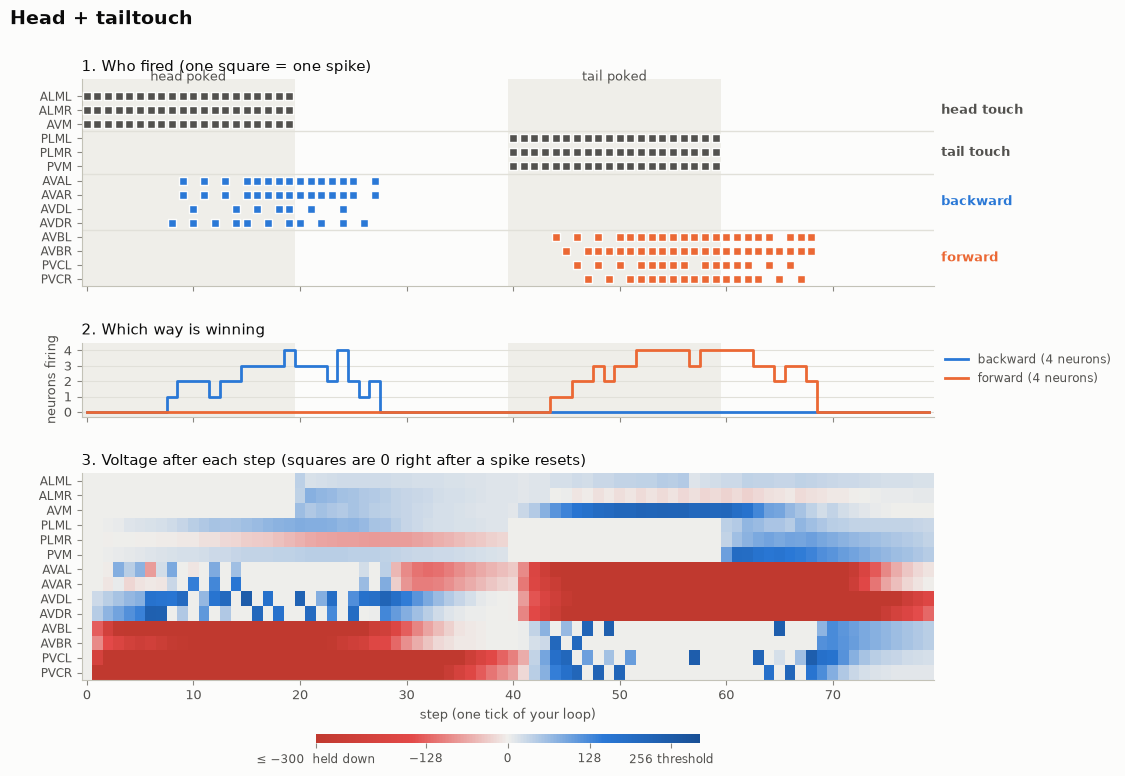

In [4]:
from plot_run import plot_run
plot_run(all_voltages, all_spikes, neurons, pokes, title="Head + tailtouch")